# PMD1 · Proyecto Integrador de Datos — Caso 01: Delivery
**Fundamentos de Gestión de Datos · TECSUP · 2026-II · Docente: Pilar Rocío Sayán Mejía**

**Equipo N.°** 11 · **Sección** B · **Archivo de datos:** `01_Delivery_PMD1.xlsx`

| N.° | Apellidos y nombres | Código | Aporte principal | Aporte (%) |
|---|---|---|---|---|
| 1 | Rodríguez Gonzales, Jhonathan Steven | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |

> **Cómo ejecutar:** *Entorno de ejecución → Ejecutar todas*. El notebook descarga los datos desde el repositorio de GitHub del curso, así que se reproduce completo desde un entorno limpio, sin archivos locales.

## 0. Problema del caso (Semana 1 — el dato como activo)

**Contexto.** Rapidito Delivery es una empresa de comida a domicilio con cinco cocinas (sedes) en Lima. Cada entrega se registra con el cliente, el plato principal, la cocina que despachó, la distancia recorrida, la cantidad de ítems y la carga que tenía la cocina en ese momento. Los datos los cargan los repartidores desde el celular y el personal de cocina, cada uno con su propio formato.

**Necesidad del negocio.** Los clientes reclaman porque el tiempo prometido en la aplicación casi nunca coincide con el tiempo real. La gerencia de operaciones quiere saber cuánto tiempo agrega cada kilómetro y si existen tipos de entrega distintos que deban prometerse con tiempos diferentes.

**Pregunta guía.** ¿Cuántos minutos adicionales de entrega se asocian a cada kilómetro de distancia y qué perfiles de entrega conviene separar para prometer tiempos más realistas?

**Objetivo.** Integrar y limpiar los registros de entregas para (1) estimar con una regresión lineal simple cuánto cambia `tiempo_entrega_min` cuando cambia `distancia_km`, y (2) segmentar las entregas con K-Means para proponer tiempos de promesa por tipo de entrega.

**Unidad de análisis.** Cada fila de la hoja **Operaciones** es **una entrega**.

**Origen y límites de los datos.** El archivo `01_Delivery_PMD1.xlsx` del repositorio del curso contiene **datos inventados para práctica** (no son observaciones reales). Por eso las conclusiones sirven para practicar el método, no para decidir sin validar con datos reales de la empresa. Los datos no traen hora del día, tráfico ni clima, así que el análisis no puede medir su efecto.

## 1. Carga reproducible: Excel en GitHub → SQLite (Semana 2)
Leemos el Excel **desde el repositorio del curso** (no desde nuestra computadora) y guardamos cada hoja como una tabla separada en SQLite.

In [1]:
# Librerías del proyecto (todas vienen instaladas en Google Colab)
import pandas as pd                     # tablas y limpieza
import numpy as np                      # cálculos numéricos
import sqlite3                          # base de datos local
import matplotlib.pyplot as plt         # gráficos
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEMILLA = 42   # misma semilla en la división y en K-Means: los resultados salen iguales cada vez
pd.set_option("display.max_columns", 30)

# Ruta RAW del caso en el repositorio del curso: así cualquiera obtiene los mismos datos
URL = "https://raw.githubusercontent.com/Rociosayan/PMD1_Fundamentos_Gestion_Datos/main/casos_PMD1/01_Delivery/01_Delivery_PMD1.xlsx"

In [2]:
# sheet_name=None trae TODAS las hojas en un diccionario {nombre_hoja: DataFrame}
hojas = pd.read_excel(URL, sheet_name=None)
for nombre, tabla in hojas.items():
    print(f"{nombre}: {tabla.shape[0]} filas x {tabla.shape[1]} columnas")

# Creamos la base y guardamos las 4 tablas del caso (LEEME solo trae notas)
# if_exists="replace" permite volver a ejecutar el notebook sin errores
conn = sqlite3.connect("delivery.db")
for nombre in ["Operaciones", "Clientes", "Catalogo", "Sedes"]:
    hojas[nombre].to_sql(nombre.lower(), conn, if_exists="replace", index=False)
pd.read_sql_query("SELECT name AS tabla FROM sqlite_master WHERE type='table'", conn)

LEEME: 16 filas x 2 columnas
Operaciones: 466 filas x 9 columnas
Clientes: 120 filas x 4 columnas
Catalogo: 20 filas x 4 columnas
Sedes: 5 filas x 3 columnas


,tabla
0,operaciones
1,clientes
2,catalogo
3,sedes


**Interpretación.** El libro trae la hoja LEEME y las cuatro tablas del caso. Cada una quedó como tabla separada en SQLite, cargada siempre desde la misma fuente: si otra persona ejecuta el notebook, obtiene las mismas cifras.

## 2. Consultas SQL básicas (Semana 2)
Primero miramos la tabla principal **sin modificarla**.

In [3]:
# SELECT + LIMIT: primeras filas de la tabla de hechos
pd.read_sql_query("SELECT * FROM operaciones LIMIT 5", conn)

,id_operacion,id_cliente,id_catalogo,id_sede,fecha,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min
0,O010001,C01002,P01008,S013,2025-02-05,5.89,4.0,39.3,26.74
1,O010002,C01067,P01002,S011,2025-07-20,5.66,3.0,30.5,34.39
2,O010003,C01109,P01013,S015,2025-05-25,2.41,1.0,14.6,18.92
3,O010004,C01086,P01010,S012,2025-09-14,5.99,4.0,33.9,31.02
4,O010005,C01071,P01020,S011,2025-09-11,9.41,7.0,58.4,66.40


In [4]:
# Funciones agregadas sobre la variable objetivo.
# COUNT(columna) no cuenta los NULL: al compararlo con COUNT(*) vemos cuántos vacíos hay.
pd.read_sql_query("""
SELECT COUNT(*)                           AS filas,
       COUNT(tiempo_entrega_min)          AS con_tiempo,
       COUNT(distancia_km)                AS con_distancia,
       ROUND(AVG(tiempo_entrega_min), 2)  AS tiempo_promedio_min,
       MIN(tiempo_entrega_min)            AS tiempo_min,
       MAX(tiempo_entrega_min)            AS tiempo_max
FROM operaciones
""", conn)

,filas,con_tiempo,con_distancia,tiempo_promedio_min,tiempo_min,tiempo_max
0,466,463,462,29.13,12.68,90.88


In [5]:
# WHERE + ORDER BY: las 5 entregas más lentas entre las que tienen distancia registrada
pd.read_sql_query("""
SELECT id_operacion, id_sede, fecha, distancia_km, carga_operativa_pct, tiempo_entrega_min
FROM operaciones
WHERE distancia_km IS NOT NULL
ORDER BY tiempo_entrega_min DESC
LIMIT 5
""", conn)

,id_operacion,id_sede,fecha,distancia_km,carga_operativa_pct,tiempo_entrega_min
0,O010445,S013,2025-11-02,10.57,57.8,90.88
1,O010077,S014,2025-07-12,9.73,59.7,86.04
2,O010149,S015,2025-10-10,9.70,56.3,84.77
3,O010182,S012,2025-02-21,10.12,55.6,81.61
4,O010067,S013,2025-11-01,10.34,66.8,73.08


**Interpretación.** Las diferencias entre `COUNT(*)` y `COUNT(columna)` muestran que faltan algunos tiempos y distancias. Las entregas más lentas permiten ver si coinciden con distancias largas o con carga alta de la cocina; ambas cosas se miden más adelante.

## 3. Modelo relacional: PK, FK y consistencia (Semana 4)

```
 clientes (PK id_cliente)   ──1:N──┐
 catalogo (PK id_catalogo)  ──1:N──┼──>  operaciones (PK id_operacion; FK id_cliente, id_catalogo, id_sede)
 sedes    (PK id_sede)      ──1:N──┘
```
- `operaciones` es la **tabla de hechos**: una fila = una entrega.
- `clientes` (nombre, ciudad, antigüedad), `catalogo` (plato, nivel, precio de referencia) y `sedes` (cocina y zona) son **tablas de dimensión**.
- **Cardinalidad 1:N:** cada cliente, plato o sede puede aparecer en **muchas** entregas, pero cada entrega tiene un solo cliente, un solo plato y una sola sede. Por eso la clave foránea va en `operaciones`, el lado "muchos".
- Los datos del cliente, del plato y de la sede están en su propia tabla y no se repiten en cada entrega: así se evitan anomalías de actualización (cambiar el nombre de una sede en un solo lugar).

In [6]:
# 1) ¿La PK es única? Si filas > claves distintas, hay entregas repetidas.
verif = []
for tabla, pk in [("operaciones","id_operacion"), ("clientes","id_cliente"), ("catalogo","id_catalogo"), ("sedes","id_sede")]:
    r = pd.read_sql_query(f"SELECT COUNT(*) AS filas, COUNT(DISTINCT {pk}) AS distintas FROM {tabla}", conn)
    verif.append({"tabla": tabla, "pk": pk, "filas": int(r.filas[0]), "claves_distintas": int(r.distintas[0])})
verificacion_pk = pd.DataFrame(verif)
verificacion_pk["pk_unica"] = verificacion_pk.filas == verificacion_pk.claves_distintas
verificacion_pk

,tabla,pk,filas,claves_distintas,pk_unica
0,operaciones,id_operacion,466,460,False
1,clientes,id_cliente,120,120,True
2,catalogo,id_catalogo,20,20,True
3,sedes,id_sede,5,5,True


In [7]:
# 2) Claves huérfanas: entregas cuya FK no existe en la tabla de dimensión.
#    LEFT JOIN conserva todas las entregas; si la dimensión queda NULL, la clave no existe.
huerfanas = {}
for tabla, fk in [("clientes","id_cliente"), ("catalogo","id_catalogo"), ("sedes","id_sede")]:
    q = f"""SELECT COUNT(*) AS n FROM operaciones o
             LEFT JOIN {tabla} t ON o.{fk} = t.{fk}
             WHERE t.{fk} IS NULL"""
    huerfanas[fk] = int(pd.read_sql_query(q, conn).n[0])
huerfanas

{'id_cliente': 0, 'id_catalogo': 0, 'id_sede': 0}

**Interpretación.** Clientes, Catalogo y Sedes tienen claves únicas. En Operaciones hay **466 filas pero 460 `id_operacion` distintos: 6 entregas repetidas**, que se tratan en la limpieza. No hay claves huérfanas: todas las entregas se pueden asociar a un cliente, un plato y una sede.

## 4. Integración con JOIN, GROUP BY, HAVING, subconsulta y VIEW (Semana 3)
Creamos la vista `vw_analitica` que une las cuatro tablas con **LEFT JOIN**, partiendo de Operaciones para no perder ninguna entrega. Seleccionamos columnas para no repetir las claves.

In [8]:
conn.execute("DROP VIEW IF EXISTS vw_analitica")
conn.execute("""
CREATE VIEW vw_analitica AS
SELECT o.*,
       c.nombre_cliente, c.ciudad, c.antiguedad_meses,
       p.nombre_item, p.nivel, p.precio_referencia_soles,
       s.nombre_sede, s.zona
FROM operaciones o
LEFT JOIN clientes c ON o.id_cliente  = c.id_cliente
LEFT JOIN catalogo p ON o.id_catalogo = p.id_catalogo
LEFT JOIN sedes    s ON o.id_sede     = s.id_sede
""")
# Comprobación de conteos: la vista debe tener las mismas filas que Operaciones
pd.read_sql_query("""
SELECT (SELECT COUNT(*) FROM operaciones)  AS filas_operaciones,
       (SELECT COUNT(*) FROM vw_analitica) AS filas_vista
""", conn)

,filas_operaciones,filas_vista
0,466,466


In [9]:
# Pregunta de negocio 1 (GROUP BY + HAVING): ¿qué cocinas tienen más de 90 entregas
# y cuál es su distancia y tiempo promedio? HAVING filtra DESPUÉS de agrupar.
pd.read_sql_query("""
SELECT nombre_sede, zona, COUNT(*) AS entregas,
       ROUND(AVG(distancia_km), 2)       AS distancia_prom_km,
       ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min
FROM vw_analitica
GROUP BY nombre_sede, zona
HAVING COUNT(*) > 90
ORDER BY tiempo_prom_min DESC
""", conn)

,nombre_sede,zona,entregas,distancia_prom_km,tiempo_prom_min
0,Rapidito Delivery Surco,Sur,102,5.43,30.19
1,Rapidito Delivery Los Olivos,Norte,92,5.96,29.56
2,Rapidito Delivery Cercado de Lima,Centro,97,5.52,27.73


In [10]:
# Pregunta de negocio 2: comportamiento por nivel del plato
pd.read_sql_query("""
SELECT nivel, COUNT(*) AS entregas,
       ROUND(AVG(items_pedido), 2)       AS items_prom,
       ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min
FROM vw_analitica
GROUP BY nivel
ORDER BY tiempo_prom_min DESC
""", conn)

,nivel,entregas,items_prom,tiempo_prom_min
0,basico,192,3.25,30.87
1,especial,105,3.18,28.43
2,intermedio,169,3.08,27.60


In [11]:
# Pregunta de negocio 3 (subconsulta): ciudades cuyo tiempo promedio supera el promedio general
pd.read_sql_query("""
SELECT ciudad, COUNT(*) AS entregas, ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min
FROM vw_analitica
GROUP BY ciudad
HAVING AVG(tiempo_entrega_min) > (SELECT AVG(tiempo_entrega_min) FROM operaciones)
ORDER BY tiempo_prom_min DESC
""", conn)

,ciudad,entregas,tiempo_prom_min
0,Piura,68,31.95
1,Arequipa,98,30.99


In [12]:
# Pregunta de negocio 4 (WHERE con dos condiciones): entregas largas (> 5 km) con cocina muy cargada (> 70 %)
pd.read_sql_query("""
SELECT COUNT(*) AS entregas_largas_y_cargadas,
       ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min,
       (SELECT ROUND(AVG(tiempo_entrega_min), 2) FROM operaciones) AS tiempo_prom_general
FROM operaciones
WHERE distancia_km > 5 AND carga_operativa_pct > 70
""", conn)

,entregas_largas_y_cargadas,tiempo_prom_min,tiempo_prom_general
0,21,41.84,29.13


**Interpretación.**
- La vista conserva las **466 entregas**. Un INNER JOIN daría el mismo número porque no hay huérfanas, pero LEFT JOIN nos protege si las hubiera.
- **HAVING:** solo 3 de las 5 cocinas superan las 90 entregas (Surco 102, Cercado 97 y Los Olivos 92). Entre ellas, Surco es la más lenta (30.19 min) y Cercado de Lima la más rápida (27.73 min). Sin el filtro, la más lenta de todas es San Miguel (zona Oeste, 31.25 min con 86 entregas).
- **Por nivel del plato:** los platos básicos tardan más en promedio (30.87 min) que los intermedios (27.60 min), aunque la cantidad de ítems es casi igual (3.25 vs 3.08).
- **Subconsulta:** los clientes de Piura (31.95 min) y Arequipa (30.99 min) superan el promedio general de 29.13 min.
- Las **21 entregas de más de 5 km con carga mayor a 70 %** tardan en promedio **41.84 min**, 12.7 min más que el promedio: distancia larga y cocina cargada se suman.

## 5. Exploración (EDA) con pandas (Semana 5)
Seguimos los cinco pasos del EDA: (1) cargar y conocer, (2) estructura y calidad, (3) una variable, (4) entre variables y (5) hallazgos. Leemos la vista desde SQLite: este DataFrame es la **tabla analítica antes de limpiar**.

In [13]:
# La tabla analítica sale de SQLite (trazable), no de un archivo editado a mano
df = pd.read_sql_query("SELECT * FROM vw_analitica", conn)
antes = df.copy()          # copia intacta para comparar antes vs después
print("Dimensiones (filas, columnas):", df.shape)
df.head()

Dimensiones (filas, columnas): (466, 17)


,id_operacion,id_cliente,id_catalogo,id_sede,fecha,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min,nombre_cliente,ciudad,antiguedad_meses,nombre_item,nivel,precio_referencia_soles,nombre_sede,zona
0,O010001,C01002,P01008,S013,2025-02-05,5.89,4.0,39.3,26.74,Gabriela Chávez Torres,Cusco,9,Ensalada de quinua,intermedio,21.58,Rapidito Delivery San Miguel,Oeste
1,O010002,C01067,P01002,S011,2025-07-20,5.66,3.0,30.5,34.39,Martín Benites Gómez,Lima,4,Pollo a la brasa 1/4,intermedio,35.22,Rapidito Delivery Los Olivos,Norte
2,O010003,C01109,P01013,S015,2025-05-25,2.41,1.0,14.6,18.92,Carlos Ramírez Castillo,Trujillo,1,Ensalada Waldorf,basico,21.38,Rapidito Delivery Surco,Sur
3,O010004,C01086,P01010,S012,2025-09-14,5.99,4.0,33.9,31.02,Diego Condori Gutiérrez,Huancayo,4,Pizza pepperoni familiar,especial,47.51,Rapidito Delivery Cercado de Lima,Centro
4,O010005,C01071,P01020,S011,2025-09-11,9.41,7.0,58.4,66.40,Andrés Reyes Paredes,Huancayo,1,Ensalada fresca de la casa,intermedio,21.74,Rapidito Delivery Los Olivos,Norte


In [14]:
# info(): tipo de dato y valores no nulos por columna. Ojo: 'fecha' llega como texto.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 466 entries, 0 to 465
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_operacion             466 non-null    str    
 1   id_cliente               466 non-null    str    
 2   id_catalogo              466 non-null    str    
 3   id_sede                  466 non-null    str    
 4   fecha                    466 non-null    str    
 5   distancia_km             462 non-null    float64
 6   items_pedido             461 non-null    float64
 7   carga_operativa_pct      466 non-null    float64
 8   tiempo_entrega_min       463 non-null    float64
 9   nombre_cliente           466 non-null    str    
 10  ciudad                   466 non-null    str    
 11  antiguedad_meses         466 non-null    int64  
 12  nombre_item              466 non-null    str    
 13  nivel                    466 non-null    str    
 14  precio_referencia_soles  466 non-null

In [15]:
# describe(): media, desviación, mínimo, cuartiles y máximo de las variables numéricas
VARS_NUM = ["distancia_km", "items_pedido", "carga_operativa_pct", "tiempo_entrega_min"]
df[VARS_NUM].describe().round(2)

,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min
count,462.00,461.00,466.00,463.00
mean,5.58,3.17,33.71,29.13
std,3.11,1.83,21.33,13.38
min,1.11,1.00,1.00,12.68
25%,2.57,1.00,15.05,18.76
50%,5.42,3.00,33.50,25.48
75%,8.66,5.00,49.50,36.23
max,11.89,9.00,90.10,90.88


In [16]:
# value_counts(): cómo se reparten las entregas por zona, nivel y ciudad (dropna=False muestra vacíos)
for col in ["zona", "nivel", "ciudad"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- zona ---
zona
Norte     181
Sur       102
Centro     97
Oeste      86
Name: count, dtype: int64 

--- nivel ---
nivel
basico        192
intermedio    169
especial      105
Name: count, dtype: int64 

--- ciudad ---
ciudad
Arequipa    98
Cusco       87
Huancayo    78
Lima        71
Piura       68
Trujillo    64
Name: count, dtype: int64 



In [17]:
# Matriz de correlaciones: ¿qué variables se mueven juntas?
# La usamos para elegir la predictora y para saber qué otras variables influyen en el tiempo.
df[VARS_NUM].corr().round(3)

,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min
distancia_km,1.000,0.779,0.845,0.724
items_pedido,0.779,1.000,0.713,0.535
carga_operativa_pct,0.845,0.713,1.000,0.626
tiempo_entrega_min,0.724,0.535,0.626,1.000


Correlación distancia-tiempo (sin limpiar): 0.7242


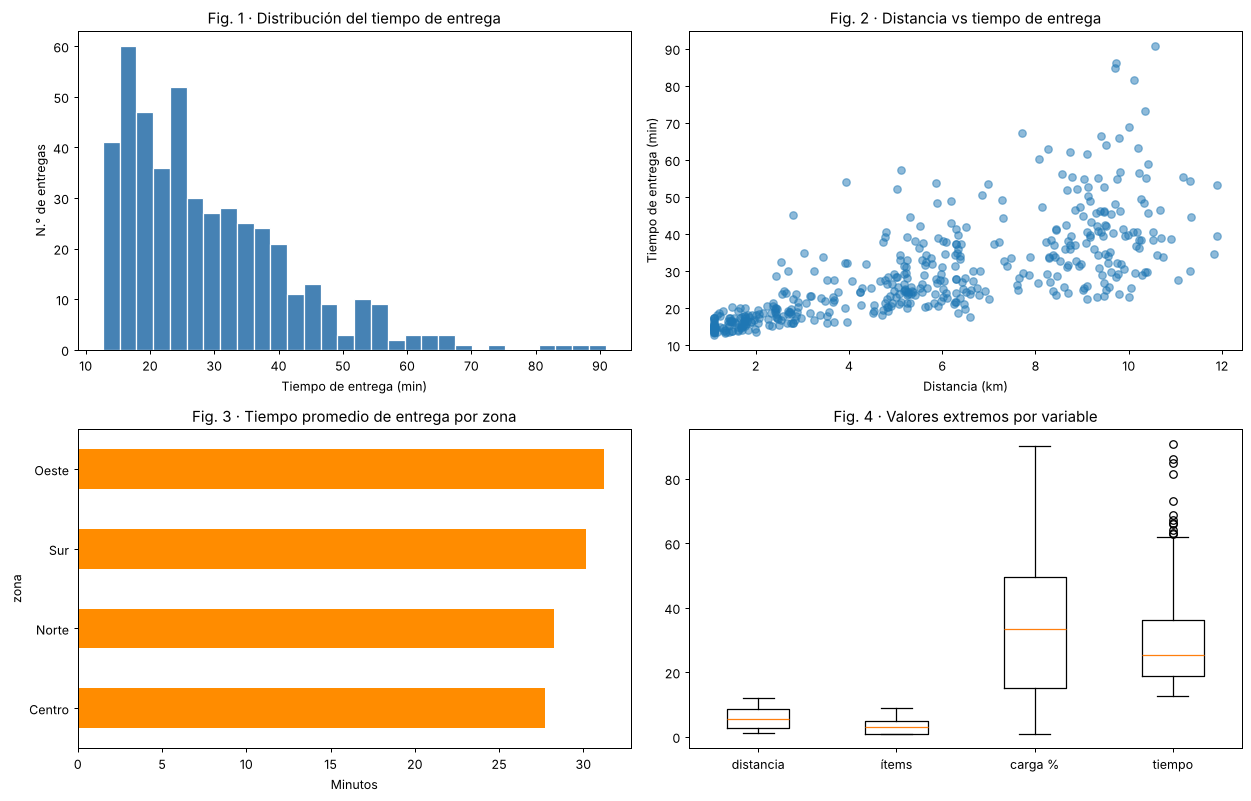

In [18]:
# Cuatro gráficos para entender los datos ANTES de limpiar
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# Fig. 1: distribución de la variable objetivo
ax[0,0].hist(df["tiempo_entrega_min"].dropna(), bins=30, color="steelblue", edgecolor="white")
ax[0,0].set_title("Fig. 1 · Distribución del tiempo de entrega")
ax[0,0].set_xlabel("Tiempo de entrega (min)"); ax[0,0].set_ylabel("N.° de entregas")

# Fig. 2: relación predictora-objetivo
ax[0,1].scatter(df["distancia_km"], df["tiempo_entrega_min"], alpha=0.5)
ax[0,1].set_title("Fig. 2 · Distancia vs tiempo de entrega")
ax[0,1].set_xlabel("Distancia (km)"); ax[0,1].set_ylabel("Tiempo de entrega (min)")

# Fig. 3: tiempo promedio por zona de la cocina
df.groupby("zona")["tiempo_entrega_min"].mean().sort_values().plot(kind="barh", ax=ax[1,0], color="darkorange")
ax[1,0].set_title("Fig. 3 · Tiempo promedio de entrega por zona"); ax[1,0].set_xlabel("Minutos")

# Fig. 4: diagramas de caja para detectar valores extremos
ax[1,1].boxplot([df[c].dropna() for c in VARS_NUM])
ax[1,1].set_xticks(range(1, 5)); ax[1,1].set_xticklabels(["distancia", "ítems", "carga %", "tiempo"])
ax[1,1].set_title("Fig. 4 · Valores extremos por variable")
plt.tight_layout(); plt.show()

print("Correlación distancia-tiempo (sin limpiar):", round(df["distancia_km"].corr(df["tiempo_entrega_min"]), 4))

**Interpretación de la exploración.**
- La tabla analítica tiene **466 filas y 17 columnas**. La **fecha llega como texto** y hay faltantes en `distancia_km` (4), `items_pedido` (5) y `tiempo_entrega_min` (3).
- La distancia va de 1.11 a 11.89 km (media 5.58 km). El tiempo va de 12.68 a 90.88 min, con **media 29.13 y mediana 25.48**: la media es mayor porque hay pocas entregas muy lentas (cola a la derecha, Fig. 1).
- **Fig. 2:** a más kilómetros, más minutos. La correlación sin limpiar es **0.7242**, lo que justifica usar `distancia_km` como predictora.
- **Fig. 3:** las diferencias entre zonas son moderadas (Centro 27.73 min, Oeste 31.25 min).
- **Fig. 4:** el tiempo es la única variable con valores extremos visibles; no hay distancias, ítems ni cargas imposibles.
- La zona Norte concentra más entregas (181) porque tiene dos cocinas.
- **Matriz de correlaciones:** la distancia es la variable más relacionada con el tiempo (0.724), por encima de la carga (0.626) y los ítems (0.535). Pero la distancia también está muy relacionada con la carga (**0.845**) y con los ítems (0.779): los pedidos lejanos suelen ser más grandes y salir con la cocina más cargada. Por eso, el efecto que la regresión atribuye a la distancia incluye en parte el de esas otras variables.

## 6. Diagnóstico y limpieza de datos (Semana 6)
Regla de trabajo: **primero medir, luego decidir, después comparar**. Ningún registro se elimina sin decir cuántos y por qué. Cada problema afecta una dimensión de la calidad del dato: **completitud** (nulos), **consistencia** (duplicados, fechas en dos formatos, espacios) y **exactitud** (valores fuera de rango o extremos). Si entra un dato malo, sale una decisión mala (*Garbage In, Garbage Out*).

In [19]:
# ---------- DIAGNÓSTICO: cuantificamos cada problema antes de tocar nada ----------
diag = []

# Nulos por columna
for col in antes.columns:
    n = int(antes[col].isna().sum())
    if n > 0:
        diag.append({"problema": "Valores nulos", "columna": col, "cantidad": n})

# Duplicados exactos (misma entrega cargada dos veces)
diag.append({"problema": "Filas duplicadas exactas", "columna": "todas", "cantidad": int(antes.duplicated().sum())})

# Fechas que no están en formato AAAA-MM-DD
fecha_txt = antes["fecha"].astype(str).str.strip()
diag.append({"problema": "Fecha en formato distinto a AAAA-MM-DD", "columna": "fecha",
             "cantidad": int((~fecha_txt.str.match(r"^\d{4}-\d{2}-\d{2}$")).sum())})

# Espacios sobrantes en textos (al inicio, al final o dobles)
COLS_TXT = ["nombre_cliente", "ciudad", "nombre_item", "nivel", "nombre_sede", "zona"]
for col in COLS_TXT:
    t = antes[col].dropna().astype(str)
    n = int(((t != t.str.strip()) | t.str.contains(r"\s{2,}")).sum())
    if n > 0:
        diag.append({"problema": "Texto con espacios sobrantes", "columna": col, "cantidad": n})

# Claves huérfanas (ya medidas con SQL)
diag.append({"problema": "Claves huérfanas", "columna": "id_cliente / id_catalogo / id_sede", "cantidad": sum(huerfanas.values())})

# Valores fuera de rango (imposibles para una entrega)
fuera = ((antes.distancia_km <= 0) | (antes.tiempo_entrega_min <= 0) | (antes.items_pedido <= 0) |
         (antes.carga_operativa_pct < 0) | (antes.carga_operativa_pct > 100))
diag.append({"problema": "Valores fuera de rango (≤ 0 o carga fuera de 0-100 %)", "columna": "numéricas", "cantidad": int(fuera.sum())})

# Valores extremos del tiempo con la regla IQR: solo los SEÑALAMOS, no los borramos automáticamente
q1, q3 = antes["tiempo_entrega_min"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_ext = int(((antes.tiempo_entrega_min < lim_inf) | (antes.tiempo_entrega_min > lim_sup)).sum())
diag.append({"problema": f"Extremos IQR del tiempo (> {lim_sup:.2f} min)", "columna": "tiempo_entrega_min", "cantidad": n_ext})

diagnostico = pd.DataFrame(diag)
diagnostico

,problema,columna,cantidad
0,Valores nulos,distancia_km,4
1,Valores nulos,items_pedido,5
2,Valores nulos,tiempo_entrega_min,3
3,Filas duplicadas exactas,todas,6
4,Fecha en formato distinto a AAAA-MM-DD,fecha,20
5,Texto con espacios sobrantes,nombre_cliente,22
6,Claves huérfanas,id_cliente / id_catalogo / id_sede,0
7,Valores fuera de rango (≤ 0 o carga fuera de 0...,numéricas,0
8,Extremos IQR del tiempo (> 62.44 min),tiempo_entrega_min,12


In [20]:
# ---------- LIMPIEZA paso a paso, con bitácora de decisiones ----------
limpio = antes.copy()
bitacora = []
def registrar(paso, motivo):
    bitacora.append({"paso": paso, "motivo": motivo, "filas_que_quedan": len(limpio)})
registrar("0. Copia de la tabla analítica", "Los datos originales no se modifican")

# 1) Duplicados exactos: una entrega repetida se contaría dos veces y pesaría doble en el modelo
limpio = limpio.drop_duplicates()
registrar("1. Eliminar duplicados exactos", "Misma entrega cargada dos veces")

# 2) Espacios: quitamos los del inicio/fin y los dobles, para que un mismo nombre no cuente como dos
for col in COLS_TXT:
    limpio[col] = limpio[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
registrar("2. Quitar espacios sobrantes en textos", "Uniformar nombres sin cambiar su contenido")

# 3) Fechas: convertimos los dos formatos (AAAA-MM-DD y D/M/AAAA) a un solo tipo fecha
txt = limpio["fecha"].astype(str).str.strip()
iso = pd.to_datetime(txt, format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(txt, format="%d/%m/%Y", errors="coerce")
limpio["fecha"] = iso.fillna(dmy)
print("Fechas que no se pudieron convertir:", int(limpio["fecha"].isna().sum()))
registrar("3. Unificar formato de fecha", "Una sola fecha válida para analizar por mes")

# 4) Valores imposibles -> se eliminan (en este caso la regla se aplica, aunque el diagnóstico encontró 0)
limpio = limpio[~((limpio.distancia_km <= 0) | (limpio.tiempo_entrega_min <= 0) | (limpio.items_pedido <= 0) |
                  (limpio.carga_operativa_pct < 0) | (limpio.carga_operativa_pct > 100))]
registrar("4. Eliminar valores imposibles", "Errores de registro, no entregas reales")

# 5) Nulos en la predictora o el objetivo: sin distancia o sin tiempo no se puede entrenar ni evaluar.
#    Imputarlos sería inventar justo la relación que queremos medir.
limpio = limpio.dropna(subset=["distancia_km", "tiempo_entrega_min"])
registrar("5. Eliminar nulos en distancia o tiempo", "Son las variables del modelo")

# 6) Nulos en items_pedido: no es variable de la regresión; imputamos con la mediana para conservar la entrega
mediana_items = limpio["items_pedido"].median()
n_imp = int(limpio["items_pedido"].isna().sum())
limpio["items_pedido"] = limpio["items_pedido"].fillna(mediana_items)
registrar(f"6. Imputar {n_imp} items_pedido con la mediana ({mediana_items:.0f})", "Variable secundaria; la mediana no se deja arrastrar por extremos")

# 7) Extremos IQR del tiempo: se CONSERVAN y se marcan. Un tiempo alto es poco común pero posible
#    (tráfico, cocina saturada); borrarlo sería quitar justamente las entregas que generan reclamos.
limpio["extremo_tiempo"] = ((limpio.tiempo_entrega_min < lim_inf) | (limpio.tiempo_entrega_min > lim_sup)).astype(int)
registrar("7. Marcar (no borrar) extremos IQR del tiempo", "Son entregas posibles; su efecto se mide en la sección 7")

bitacora = pd.DataFrame(bitacora)
bitacora

Fechas que no se pudieron convertir: 0


,paso,motivo,filas_que_quedan
0,0. Copia de la tabla analítica,Los datos originales no se modifican,466
1,1. Eliminar duplicados exactos,Misma entrega cargada dos veces,460
2,2. Quitar espacios sobrantes en textos,Uniformar nombres sin cambiar su contenido,460
3,3. Unificar formato de fecha,Una sola fecha válida para analizar por mes,460
4,4. Eliminar valores imposibles,"Errores de registro, no entregas reales",460
5,5. Eliminar nulos en distancia o tiempo,Son las variables del modelo,453
6,6. Imputar 5 items_pedido con la mediana (3),Variable secundaria; la mediana no se deja arr...,453
7,7. Marcar (no borrar) extremos IQR del tiempo,Son entregas posibles; su efecto se mide en la...,453


In [21]:
# ---------- ANTES vs DESPUÉS ----------
def resumen(d):
    return {
        "filas": len(d),
        "nulos_totales": int(d[antes.columns].isna().sum().sum()),
        "duplicados_exactos": int(d[antes.columns].duplicated().sum()),
        "fecha_como_tipo_fecha": bool(pd.api.types.is_datetime64_any_dtype(d["fecha"])),
        "tiempo_promedio_min": round(d["tiempo_entrega_min"].mean(), 2),
        "correlacion_distancia_tiempo": round(d["distancia_km"].corr(d["tiempo_entrega_min"]), 4),
    }
comparacion = pd.DataFrame({"antes": resumen(antes), "despues": resumen(limpio)})
print(f"Se conserva el {len(limpio) / len(antes):.1%} de las filas ({len(limpio)} de {len(antes)})")
comparacion

Se conserva el 97.2% de las filas (453 de 466)


,antes,despues
filas,466,453
nulos_totales,12,0
duplicados_exactos,6,0
fecha_como_tipo_fecha,False,True
tiempo_promedio_min,29.13,29.26
correlacion_distancia_tiempo,0.7242,0.7222


In [22]:
# Guardamos la tabla limpia en SQLite como dataset_limpio (la fecha se guarda como texto AAAA-MM-DD)
guardar = limpio.copy()
guardar["fecha"] = guardar["fecha"].dt.strftime("%Y-%m-%d")
guardar.to_sql("dataset_limpio", conn, if_exists="replace", index=False)

# Comprobamos con SQL que se guardó bien
pd.read_sql_query("""
SELECT COUNT(*) AS filas,
       SUM(CASE WHEN distancia_km IS NULL OR tiempo_entrega_min IS NULL THEN 1 ELSE 0 END) AS nulos_modelo,
       SUM(extremo_tiempo) AS extremos_marcados,
       ROUND(AVG(tiempo_entrega_min), 2) AS tiempo_prom_min
FROM dataset_limpio
""", conn)

,filas,nulos_modelo,extremos_marcados,tiempo_prom_min
0,453,0,12,29.26


**Interpretación y justificación de la limpieza.**
- **Duplicados (6):** misma entrega con los mismos valores cargada dos veces → se eliminan.
- **Espacios sobrantes (22 en `nombre_cliente`):** se quitan; no cambia el dato, solo lo uniforma.
- **Fechas (20 en formato D/M/AAAA):** se convierten todas a un solo formato de fecha.
- **Valores imposibles:** la regla se aplica, pero el diagnóstico no encontró ninguno.
- **Nulos en distancia o tiempo (7 filas):** se eliminan; son el 1.5 % de la base e imputarlos inventaría la relación que se quiere medir.
- **Nulos en `items_pedido` (5):** se imputan con la mediana (3 ítems) para no perder la entrega.
- **Extremos del tiempo (12, más de 62.44 min):** **se conservan y se marcan**. No son imposibles (una entrega puede demorar por tráfico o cocina saturada) y son justamente las que generan reclamos. En la sección 7 se mide cuánto cambian el modelo.
- **Resultado:** quedan **453 de 466 entregas (97.2 %)**, sin nulos ni duplicados y con la fecha como fecha.

## 7. Regresión lineal simple (Semana 6)
**Pregunta:** ¿cuántos minutos adicionales de entrega se asocian a cada kilómetro de distancia?
- **Objetivo (Y): `tiempo_entrega_min`.** Es lo que la empresa promete y lo que los clientes reclaman.
- **Predictora (X): `distancia_km`.** Es la predictora sugerida por el caso, tiene sentido operativo (más recorrido, más tiempo) y fue la más correlacionada con el tiempo en el EDA. Además se conoce **antes** de despachar, así que no hay *fuga de información*.
- Separamos **80 % entrenamiento / 20 % prueba**: el modelo se evalúa con entregas que nunca vio.

In [23]:
# Leemos desde SQLite la tabla limpia (demuestra que el flujo SQL -> pandas funciona)
datos = pd.read_sql_query("SELECT id_operacion, distancia_km, tiempo_entrega_min, extremo_tiempo FROM dataset_limpio", conn)
X = datos[["distancia_km"]]          # doble corchete: scikit-learn espera una tabla (2D) para X
y = datos["tiempo_entrega_min"]

# Guardamos también el id para poder rastrear cada predicción
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, datos["id_operacion"], test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", len(X_train), "entregas | Prueba:", len(X_test), "entregas")

modelo = LinearRegression().fit(X_train, y_train)   # aprende la recta SOLO con entrenamiento
b0, b1 = modelo.intercept_, modelo.coef_[0]
y_pred = modelo.predict(X_test)                     # predice entregas que no vio

r2_train = modelo.score(X_train, y_train)
r2   = r2_score(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test, y_pred)
print(f"Ecuación: tiempo_entrega_min = {b0:.2f} + {b1:.2f} x distancia_km")
print(f"R² prueba = {r2:.3f} | MSE = {mse:.2f} | RMSE = {rmse:.2f} min | MAE = {mae:.2f} min")
print(f"R² entrenamiento = {r2_train:.3f}  (si fuera mucho mayor que en prueba, el modelo no generaliza bien)")

Entrenamiento: 362 entregas | Prueba: 91 entregas
Ecuación: tiempo_entrega_min = 11.55 + 3.17 x distancia_km
R² prueba = 0.529 | MSE = 63.52 | RMSE = 7.97 min | MAE = 6.00 min
R² entrenamiento = 0.520  (si fuera mucho mayor que en prueba, el modelo no generaliza bien)


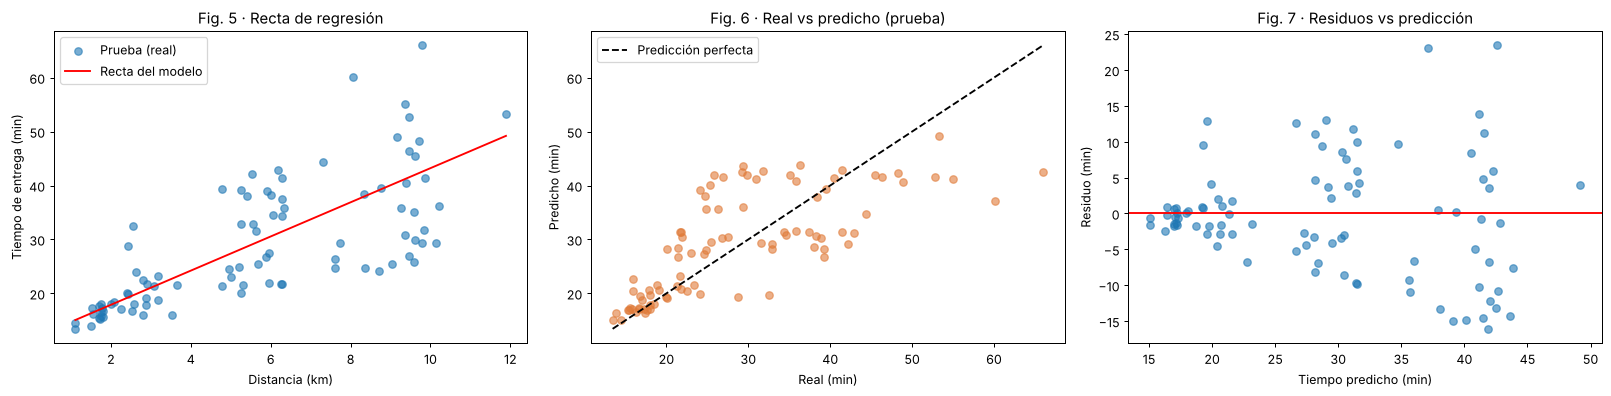

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# Fig. 5: recta ajustada sobre los datos de prueba
xs = np.linspace(X["distancia_km"].min(), X["distancia_km"].max(), 50)
ax[0].scatter(X_test["distancia_km"], y_test, alpha=0.6, label="Prueba (real)")
ax[0].plot(xs, b0 + b1 * xs, color="red", label="Recta del modelo")
ax[0].set_title("Fig. 5 · Recta de regresión"); ax[0].set_xlabel("Distancia (km)"); ax[0].set_ylabel("Tiempo de entrega (min)")
ax[0].legend()

# Fig. 6: real vs predicho; si el modelo fuera perfecto, todo caería sobre la diagonal
ax[1].scatter(y_test, y_pred, alpha=0.6, color="#E07B39")
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[1].plot(lim, lim, "k--", label="Predicción perfecta")
ax[1].set_title("Fig. 6 · Real vs predicho (prueba)"); ax[1].set_xlabel("Real (min)"); ax[1].set_ylabel("Predicho (min)")
ax[1].legend()

# Fig. 7: residuos; para cumplir el supuesto lineal no deberían formar curva ni embudo
residuos = y_test - y_pred
ax[2].scatter(y_pred, residuos, alpha=0.6); ax[2].axhline(0, color="red")
ax[2].set_title("Fig. 7 · Residuos vs predicción"); ax[2].set_xlabel("Tiempo predicho (min)"); ax[2].set_ylabel("Residuo (min)")
plt.tight_layout(); plt.show()

In [25]:
# Guardamos reales y estimados en SQLite (lo pide la consigna), con el id para rastrear cada entrega
predicciones = pd.DataFrame({
    "id_operacion": id_test.values,
    "distancia_km": X_test["distancia_km"].values,
    "tiempo_real_min": y_test.values,
    "tiempo_estimado_min": y_pred.round(2),
})
predicciones["error_min"] = (predicciones["tiempo_real_min"] - predicciones["tiempo_estimado_min"]).round(2)
predicciones.to_sql("predicciones_regresion", conn, if_exists="replace", index=False)
pd.read_sql_query("SELECT * FROM predicciones_regresion LIMIT 5", conn)

,id_operacion,distancia_km,tiempo_real_min,tiempo_estimado_min,error_min
0,O010358,5.25,32.90,28.18,4.72
1,O010041,9.35,55.03,41.16,13.87
2,O010367,2.88,19.08,20.67,-1.59
3,O010364,9.59,35.15,41.92,-6.77
4,O010158,2.26,17.02,18.71,-1.69


In [26]:
# Uso del modelo: tiempo estimado para distancias típicas, con el margen del RMSE
def estimar(km):
    return b0 + b1 * km
for km in [2, 5, 8, 11]:
    print(f"{km:>2} km -> {estimar(km):.1f} min estimados (± {rmse:.1f} min)")

 2 km -> 17.9 min estimados (± 8.0 min)
 5 km -> 27.4 min estimados (± 8.0 min)
 8 km -> 36.9 min estimados (± 8.0 min)
11 km -> 46.4 min estimados (± 8.0 min)


In [27]:
# Sensibilidad: ¿cuánto cambia el modelo si se retiran los extremos del tiempo?
# Usamos la MISMA división entrenamiento/prueba para comparar en igualdad de condiciones.
mask_tr = (datos.loc[X_train.index, "extremo_tiempo"] == 0).values
mask_te = (datos.loc[X_test.index, "extremo_tiempo"] == 0).values
m_sin = LinearRegression().fit(X_train[mask_tr], y_train[mask_tr])
pred_sin = m_sin.predict(X_test[mask_te])
sensibilidad = pd.DataFrame({
    "con extremos (modelo elegido)": [len(X_train) + len(X_test), b1, b0, r2, rmse],
    "sin extremos": [int(mask_tr.sum() + mask_te.sum()), m_sin.coef_[0], m_sin.intercept_,
                     r2_score(y_test[mask_te], pred_sin), np.sqrt(mean_squared_error(y_test[mask_te], pred_sin))],
}, index=["entregas", "pendiente (min/km)", "intercepto (min)", "R² prueba", "RMSE prueba (min)"]).round(3)
sensibilidad

,con extremos (modelo elegido),sin extremos
entregas,453.000,441.000
pendiente (min/km),3.166,2.744
intercepto (min),11.553,12.888
R² prueba,0.529,0.536
RMSE prueba (min),7.970,7.485


**Interpretación de la regresión.**
- **Ecuación:** tiempo_entrega_min = 11.55 + 3.17 × distancia_km (362 entregas de entrenamiento, 91 de prueba).
- **Pendiente (β₁ = 3.17):** en promedio, **cada kilómetro adicional se asocia con 3.17 minutos más de entrega**. Una entrega de 5 km se estima en 27.4 min y una de 8 km en 36.9 min.
- **Intercepto (β₀ = 11.55 min):** tiempo base estimado antes de recorrer distancia (preparación y salida). No hay entregas a menos de 1.11 km, así que no se interpreta literalmente como "0 km".
- **R² de prueba = 0.529:** la distancia explica cerca del **53 %** de la variación del tiempo en entregas que el modelo no vio; el 47 % restante depende de otros factores.
- **RMSE = 7.97 min y MAE = 6.00 min:** el error típico es de unos 8 minutos y el error absoluto promedio de 6 minutos, sobre un tiempo medio de 29.26 min.
- **R² entrenamiento (0.520) ≈ R² prueba (0.529):** el modelo se comporta igual con datos nuevos; no hay sobreajuste.
- **Residuos (Fig. 7):** forman un **embudo**: en entregas cortas el error es de pocos minutos, pero en las largas llega a ±15–23 min. No se cumple la **homocedasticidad** (error de tamaño parecido en todo el rango), así que **un solo margen de ±8 min queda corto para las entregas largas** (se cuantifica por segmento en la sección 8).
- **Sensibilidad:** sin los 12 extremos, la pendiente baja a 2.74 min/km y el R² casi no cambia (0.536). Mantenemos el modelo **con** extremos: esas entregas son posibles y son las que generan reclamos; quitarlas haría que el modelo prometa tiempos demasiado optimistas para las entregas largas.
- **Límites:** una sola variable; muestra **asociación, no causalidad**; parte del efecto de la distancia es en realidad carga e ítems (correlación 0.845 y 0.779); vale solo entre 1.11 y 11.89 km; los datos son sintéticos.

## 8. Segmentación con K-Means (Semana 7 — clustering)
- **¿Qué representa cada fila?** Cada fila de `dataset_limpio` es **una entrega**.
- **Tabla:** se segmenta `dataset_limpio`, la tabla que dejó la limpieza, no los datos originales.
- **Variables elegidas:** `distancia_km`, `items_pedido`, `carga_operativa_pct` y `tiempo_entrega_min`. Son numéricas y describen el tipo de entrega que menciona la gerencia: cortas y ligeras, largas y pesadas, y en hora de máxima carga.
- **Variables descartadas:** `precio_referencia_soles` y `antiguedad_meses` describen el plato y el cliente, no la entrega. Las categóricas (`zona`, `nivel`, `ciudad`) no se meten como códigos 1, 2, 3; se usan solo para interpretar los grupos.
- **Escalado:** las variables tienen unidades distintas (km, unidades, %, minutos). Sin `StandardScaler`, la carga (de 1 a 90) dominaría a los ítems (de 1 a 9) en la distancia entre puntos.
- **Atípicos:** K-Means es sensible a ellos; los 12 tiempos extremos se conservaron (sección 6) y quedarán en el grupo de entregas largas.

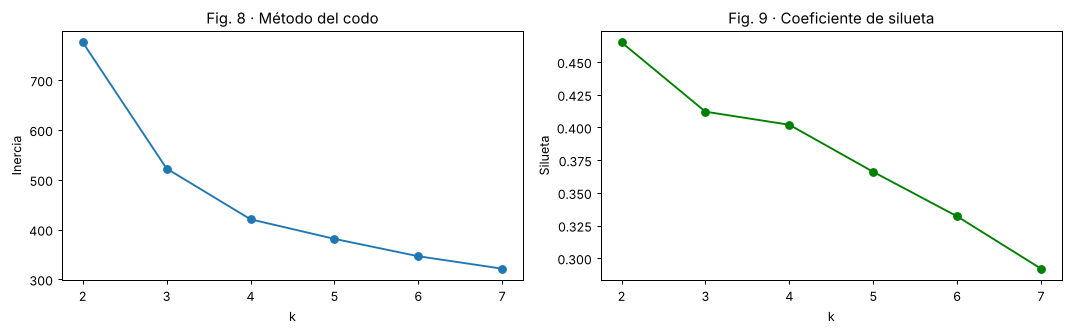

,k,inercia,silueta
0,2,775.9,0.465
1,3,522.5,0.412
2,4,420.6,0.402
3,5,381.3,0.366
4,6,346.4,0.332
5,7,321.4,0.292


In [28]:
VARS_K = ["distancia_km", "items_pedido", "carga_operativa_pct", "tiempo_entrega_min"]
seg = pd.read_sql_query(f"SELECT id_operacion, {', '.join(VARS_K)} FROM dataset_limpio", conn)
escalador = StandardScaler()
Z = escalador.fit_transform(seg[VARS_K])             # cada variable queda con media 0 y desviación 1

# Probamos k = 2..7 y medimos inercia (método del codo) y silueta (qué tan separados quedan los grupos)
pruebas = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    pruebas.append({"k": k, "inercia": round(km_k.inertia_, 1), "silueta": round(silhouette_score(Z, km_k.labels_), 3)})
pruebas = pd.DataFrame(pruebas)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(pruebas.k, pruebas.inercia, "o-"); ax[0].set_title("Fig. 8 · Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(pruebas.k, pruebas.silueta, "o-", color="green"); ax[1].set_title("Fig. 9 · Coeficiente de silueta"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silueta")
plt.tight_layout(); plt.show()
pruebas

In [29]:
K = 3   # justificación en la celda de interpretación (codo + silueta + los tres perfiles que pide la gerencia)
km = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Z)
seg["segmento"] = km.labels_

# Perfil de cada segmento en las unidades ORIGINALES (no escaladas), para leerlo en lenguaje de negocio
perfil = seg.groupby("segmento")[VARS_K].mean().round(2)
perfil["entregas"] = seg["segmento"].value_counts().sort_index()
perfil["% del total"] = (perfil["entregas"] / len(seg) * 100).round(1)
perfil

,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min,entregas,% del total
segmento,,,,,,
0,9.41,5.14,58.18,41.85,142,31.3
1,5.68,3.20,34.50,28.95,153,33.8
2,2.14,1.44,12.04,18.25,158,34.9


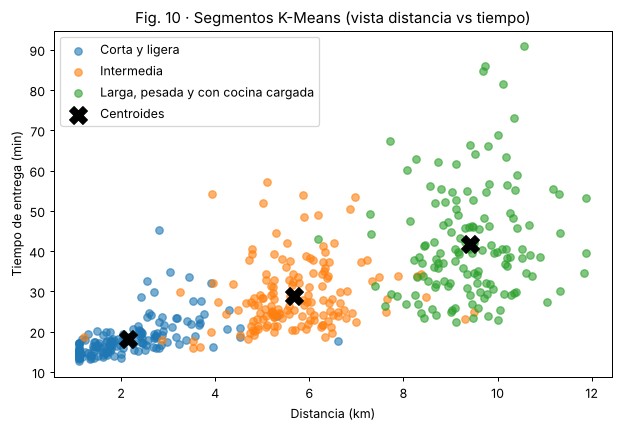

,nombre_segmento,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min,entregas,% del total
segmento,,,,,,,
0,"Larga, pesada y con cocina cargada",9.41,5.14,58.18,41.85,142,31.3
1,Intermedia,5.68,3.20,34.50,28.95,153,33.8
2,Corta y ligera,2.14,1.44,12.04,18.25,158,34.9


In [30]:
# Nombre de negocio de cada segmento: ordenamos los grupos por distancia promedio.
# Al revisar el perfil vimos que distancia, ítems y carga suben JUNTAS de un grupo a otro,
# por eso los nombres describen las tres cosas a la vez.
orden = perfil.sort_values("distancia_km").index.tolist()
nombres = {orden[0]: "Corta y ligera", orden[1]: "Intermedia", orden[2]: "Larga, pesada y con cocina cargada"}
seg["nombre_segmento"] = seg["segmento"].map(nombres)
perfil.insert(0, "nombre_segmento", perfil.index.map(nombres))

# Guardamos la asignación de grupo en SQLite (lo pide la consigna)
seg.to_sql("segmentos_kmeans", conn, if_exists="replace", index=False)

# Centroides en unidades originales: se "desescalan" con inverse_transform
centroides = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=VARS_K)

plt.figure(figsize=(8, 5))
for s, g in seg.groupby("nombre_segmento"):
    plt.scatter(g["distancia_km"], g["tiempo_entrega_min"], alpha=0.6, label=s)
plt.scatter(centroides["distancia_km"], centroides["tiempo_entrega_min"], marker="X", s=200, c="black", label="Centroides")
plt.xlabel("Distancia (km)"); plt.ylabel("Tiempo de entrega (min)")
plt.title("Fig. 10 · Segmentos K-Means (vista distancia vs tiempo)"); plt.legend(); plt.show()
perfil

In [31]:
# Tiempos por segmento: promedio, mediana y percentil 80 (tiempo que cumple el 80 % de las entregas del grupo)
# y error del modelo de regresión en las entregas de prueba de cada segmento.
t = seg.merge(predicciones[["id_operacion", "error_min"]], on="id_operacion", how="left")
tiempos_segmento = t.groupby("nombre_segmento").agg(
    entregas=("tiempo_entrega_min", "size"),
    tiempo_promedio=("tiempo_entrega_min", "mean"),
    tiempo_mediana=("tiempo_entrega_min", "median"),
    tiempo_p80=("tiempo_entrega_min", lambda x: x.quantile(0.8)),
    rmse_modelo_prueba=("error_min", lambda e: np.sqrt((e.dropna() ** 2).mean())),
).round(2).sort_values("tiempo_promedio")
tiempos_segmento

,entregas,tiempo_promedio,tiempo_mediana,tiempo_p80,rmse_modelo_prueba
nombre_segmento,,,,,
Corta y ligera,158,18.25,17.25,20.22,3.31
Intermedia,153,28.95,27.18,34.41,7.28
"Larga, pesada y con cocina cargada",142,41.85,39.52,52.49,11.39


In [32]:
# Los segmentos quedaron guardados en SQLite: cualquiera puede consultarlos sin repetir el modelo
pd.read_sql_query("""
SELECT nombre_segmento, COUNT(*) AS entregas,
       ROUND(AVG(distancia_km), 2)       AS distancia_prom_km,
       ROUND(AVG(tiempo_entrega_min), 1) AS tiempo_prom_min
FROM segmentos_kmeans
GROUP BY nombre_segmento
ORDER BY tiempo_prom_min
""", conn)

,nombre_segmento,entregas,distancia_prom_km,tiempo_prom_min
0,Corta y ligera,158,2.14,18.2
1,Intermedia,153,5.68,28.9
2,"Larga, pesada y con cocina cargada",142,9.41,41.8


In [33]:
# Asignar entregas nuevas a un segmento: se escalan con transform() (no fit_transform),
# usando el promedio y la desviación de los datos con que se entrenó el modelo.
nuevas = pd.DataFrame({"distancia_km": [2.0, 6.0, 10.0], "items_pedido": [1, 3, 6],
                       "carga_operativa_pct": [10, 35, 65], "tiempo_entrega_min": [17, 29, 45]})
nuevas["segmento_asignado"] = pd.Series(km.predict(escalador.transform(nuevas[VARS_K]))).map(nombres)
nuevas

,distancia_km,items_pedido,carga_operativa_pct,tiempo_entrega_min,segmento_asignado
0,2.0,1,10,17,Corta y ligera
1,6.0,3,35,29,Intermedia
2,10.0,6,65,45,"Larga, pesada y con cocina cargada"


**Elección de k.** La silueta es mayor en k = 2 (0.465), pero esa partición solo separa entregas cercanas de lejanas. En k = 3 la inercia tiene su mayor caída (776 → 523) y después baja más lento (523 → 421 en k = 4); la silueta sigue siendo buena (0.412) y aparece un grupo intermedio útil para prometer tiempos. Elegimos **k = 3**.

**Perfiles (promedios en unidades originales) y acción por segmento:**

| Segmento | Distancia | Ítems | Carga | Tiempo prom. | Percentil 80 | % entregas | Acción sugerida |
|---|---|---|---|---|---|---|---|
| Corta y ligera | 2.14 km | 1.4 | 12 % | 18.2 min | 20.2 min | 34.9 % | Prometer ~20 min: el modelo acierta (error típico 3.3 min) |
| Intermedia | 5.68 km | 3.2 | 35 % | 28.9 min | 34.4 min | 33.8 % | Prometer el tiempo del modelo con margen de ~7 min |
| Larga, pesada y con cocina cargada | 9.41 km | 5.1 | 58 % | 41.8 min | 52.5 min | 31.3 % | Prometer un rango amplio (hasta ~52 min) y reforzar repartidores en horas de carga alta |

- Los tres grupos se ordenan a la vez por distancia, ítems y carga: no aparece un grupo de "cocina cargada con distancia corta", porque en estos datos la carga sube junto con la distancia (correlación 0.845).
- El error del modelo crece de un segmento a otro (3.3 → 7.3 → 11.4 min en prueba), lo que confirma el embudo de la Fig. 7.
- **Límite:** la silueta de 0.41 indica grupos razonablemente separados, pero con zonas de frontera (Fig. 10): con datos continuos no hay cortes nítidos. Los segmentos **describen** tipos de entrega; no explican la **causa** de la demora.

**Lista de control de la Fase 4.**
1. Cada fila de `dataset_limpio` es una entrega.
2. Variables: distancia, ítems, carga y tiempo; se descartaron precio, antigüedad y las categóricas.
3. Se escalaron con `StandardScaler`.
4. k = 3 por el codo, la silueta y el criterio de negocio.
5. Segmentos: Corta y ligera, Intermedia, y Larga, pesada y con cocina cargada.
6. Cada uno tiene una acción propuesta (tabla de arriba).
7. La asignación se guardó en SQLite en la tabla `segmentos_kmeans`.

## 9. Cifras clave (para que el informe coincida con el Colab) y tablas creadas

In [34]:
# Todo sale de variables calculadas arriba: se copia al informe desde aquí, sin escribir cifras a mano
resumen_final = {
    "filas_originales": len(antes), "filas_limpias": len(limpio),
    "porcentaje_conservado": round(len(limpio) / len(antes) * 100, 1),
    "duplicados_exactos": int(antes.duplicated().sum()), "nulos_originales": int(antes.isna().sum().sum()),
    "extremos_tiempo_conservados": int(limpio["extremo_tiempo"].sum()),
    "corr_antes": round(antes["distancia_km"].corr(antes["tiempo_entrega_min"]), 4),
    "corr_despues": round(limpio["distancia_km"].corr(limpio["tiempo_entrega_min"]), 4),
    "intercepto_b0": round(b0, 3), "pendiente_b1": round(b1, 3),
    "r2_entrenamiento": round(r2_train, 3), "r2_prueba": round(r2, 3),
    "mse": round(mse, 2), "rmse": round(rmse, 2), "mae": round(mae, 2),
    "n_train": len(X_train), "n_test": len(X_test),
    "k_elegido": K, "silueta_k": round(silhouette_score(Z, km.labels_), 3),
}
for k_, v_ in resumen_final.items():
    print(f"{k_:28s}: {v_}")
print("\nTablas y vistas en la base:")
pd.read_sql_query("SELECT type, name FROM sqlite_master WHERE type IN ('table','view') ORDER BY type, name", conn)

filas_originales            : 466
filas_limpias               : 453
porcentaje_conservado       : 97.2
duplicados_exactos          : 6
nulos_originales            : 12
extremos_tiempo_conservados : 12
corr_antes                  : 0.7242
corr_despues                : 0.7222
intercepto_b0               : 11.553
pendiente_b1                : 3.166
r2_entrenamiento            : 0.52
r2_prueba                   : 0.529
mse                         : 63.52
rmse                        : 7.97
mae                         : 6.0
n_train                     : 362
n_test                      : 91
k_elegido                   : 3
silueta_k                   : 0.412

Tablas y vistas en la base:


,type,name
0,table,catalogo
1,table,clientes
2,table,dataset_limpio
3,table,operaciones
4,table,predicciones_regresion
5,table,sedes
6,table,segmentos_kmeans
7,view,vw_analitica


## 10. Conclusiones y recomendación (con palabras del equipo)
1. **Integración:** las cuatro tablas se unieron con LEFT JOIN sin perder ninguna de las 466 entregas y sin claves huérfanas. Se detectaron 6 entregas duplicadas.
2. **Calidad:** había 12 nulos, 6 duplicados, 20 fechas en otro formato y 22 nombres con espacios sobrantes. Tras la limpieza quedan 453 entregas (97.2 %) sin nulos ni duplicados; los 12 tiempos extremos se conservaron porque son entregas posibles.
3. **Regresión:** cada kilómetro adicional se asocia con unos **3.2 minutos más** sobre una base de unos 11.6 minutos. La distancia explica cerca de la mitad de la variación (R² de prueba ≈ 0.53) y el error típico es de unos 8 minutos.
4. **Segmentos:** K-Means (k = 3, silueta 0.41) separa entregas cortas y ligeras (34.9 %, 18.2 min), intermedias (33.8 %, 28.9 min) y largas, pesadas y con cocina cargada (31.3 %, 41.8 min). En este último grupo el tiempo varía mucho: el 20 % de sus entregas supera los 52.5 min.

**Recomendación:** calcular el tiempo prometido en la aplicación como **11.6 min + 3.2 min por km**, pero con un **margen que dependa del tipo de entrega**: unos ±3 min en las cortas, ±7 min en las intermedias y ±11 min en las largas (error típico del modelo en cada segmento). En las entregas largas, prometer un rango (por ejemplo "40 a 52 min") en vez de un número único, y reforzar repartidores cuando la cocina supere el 50 % de carga.

**Lo que este análisis no permite afirmar:** la regresión muestra **asociación, no causalidad** (no prueba que la distancia *cause* todo el retraso); solo vale para distancias de 1 a 12 km; deja fuera la carga de la cocina, los ítems y el tráfico; y los segmentos son orientativos. Además, los datos son sintéticos: antes de aplicarlo hay que validarlo con datos reales de la empresa.